In [19]:
%matplotlib widget
import pickle
import pyrfu
from pyrfu import mms
from pyrfu.plot import plot_line, plot_spectr, make_labels
import matplotlib
import matplotlib.patches as patches
from matplotlib.ticker import ScalarFormatter

from matplotlib import pyplot as plt
import pickle
import numpy as np
from copy import deepcopy
import xarray as xr

pyrfu.plot.set_color_cycle(pal = "pyrfu")
mms.db_init(default="local", local="/data/mms")


[07-Feb-26 17:33:02] INFO: Updating MMS data access configuration in /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/pyrfu/mms/config.json...
[07-Feb-26 17:33:02] INFO: Updating MMS SDC credentials in /homelocal/apostolosk/.config/python_keyring...


In [2]:
# w_ti = 10
# ss = "b"
# with open(f"epoch_analysis_{w_ti}{ss}_84DFs.pickle", 'rb') as file:
#     dict_ts_all = pickle.load(file)

In [3]:
# tints = [[str(dict_ts_all[it]["tint"][0]), str(dict_ts_all[it]["tint"][1])] for it in dict_ts_all.keys()]

In [4]:
# dpf_feeps_alle_e = [mms.get_feeps_alleyes(f"fluxe_brst_l2", tints[0], mms_id, verbose = False) for mms_id in range(1, 5)]
# dpf_feeps_e_corr = [mms.feeps_corrections(deepcopy(dpf_feeps_alle_e[i])) for i in range(4)]
# dpf_feeps_e_corr = [mms.feeps_remove_sunlit_sectors(deepcopy(dpf_feeps_e_corr[i]), outliers_q=0.99) for i in range(4)]
# dpf_feeps_omni_e = [mms.feeps_omni(dpf_feeps_e_corr[i],) for i in range(4)]
    


In [5]:
tint = [np.str_('2017-07-24T12:48:35.379461558'),
 np.str_('2017-07-24T12:49:43.940466378')]

In [6]:
dpf_feeps_alle_e = [mms.get_feeps_alleyes(f"fluxe_brst_l2", tint, mms_id, verbose = False) for mms_id in range(1, 5)]
dpf_feeps_e_corr = [mms.feeps_corrections(deepcopy(dpf_feeps_alle_e[i])) for i in range(4)]
dpf_feeps_e_corr_new = [mms.feeps_remove_sunlit_sectors(deepcopy(dpf_feeps_e_corr[i]), outliers_q=0.99) for i in range(4)]
dpf_feeps_omni_e = [mms.feeps_omni(dpf_feeps_e_corr[i],) for i in range(4)]
dpf_feeps_omni_e_new = [mms.feeps_omni(dpf_feeps_e_corr_new[i],) for i in range(4)]

In [7]:
import matplotlib
matplotlib.rcParams["text.usetex"] = True
matplotlib.rcParams["font.family"] = "serif"

matplotlib.rcParams["font.size"] = "20"

[07-Feb-26 17:31:18] WARNING: <>:53: SyntaxWarning: invalid escape sequence '\#'

[07-Feb-26 17:31:18] WARNING: <>:58: SyntaxWarning: invalid escape sequence '\,'

[07-Feb-26 17:31:18] WARNING: <>:53: SyntaxWarning: invalid escape sequence '\#'

[07-Feb-26 17:31:18] WARNING: <>:58: SyntaxWarning: invalid escape sequence '\,'

[07-Feb-26 17:31:18] WARNING: /tmp/ipykernel_283693/1268779468.py:53: SyntaxWarning: invalid escape sequence '\#'
  axs[i +2, 0].set_ylabel(ylabel = f'Eye \#{num}' ,  color = "black",)

[07-Feb-26 17:31:18] WARNING: /tmp/ipykernel_283693/1268779468.py:58: SyntaxWarning: invalid escape sequence '\,'
  axs[i+2, 0].text(-0.18, 0.8, s = "$E\,[\mathrm{keV}]$", transform = axs[i+2, 0].transAxes, ha = "center", weight = "bold", rotation = 90, )



[[Text(0, -20.0, ''),
  Text(0, 0.0, ''),
  Text(0, 20.0, ''),
  Text(0, 40.0, ''),
  Text(0, 60.0, ''),
  Text(0, 80.0, '')],
 [Text(0, 50.0, ''), Text(0, 100.0, ''), Text(0, 400.0, '')],
 [Text(0, 50.0, ''), Text(0, 100.0, ''), Text(0, 400.0, '')],
 [Text(0, 50.0, ''), Text(0, 100.0, ''), Text(0, 400.0, '')],
 [Text(0, 50.0, ''), Text(0, 100.0, ''), Text(0, 400.0, '')],
 [Text(0, 50.0, ''), Text(0, 100.0, ''), Text(0, 400.0, '')],
 [Text(0, 50.0, ''), Text(0, 100.0, ''), Text(0, 400.0, '')],
 [Text(0, 50.0, ''), Text(0, 100.0, ''), Text(0, 400.0, '')],
 [Text(0, 50.0, ''), Text(0, 100.0, ''), Text(0, 400.0, '')],
 [Text(0, 50.0, ''), Text(0, 100.0, ''), Text(0, 400.0, '')],
 [Text(0, 50.0, ''), Text(0, 100.0, ''), Text(0, 400.0, '')],
 [Text(0, 50.0, ''), Text(0, 100.0, ''), Text(0, 400.0, '')],
 [Text(0, 50.0, ''), Text(0, 100.0, ''), Text(0, 400.0, '')]]

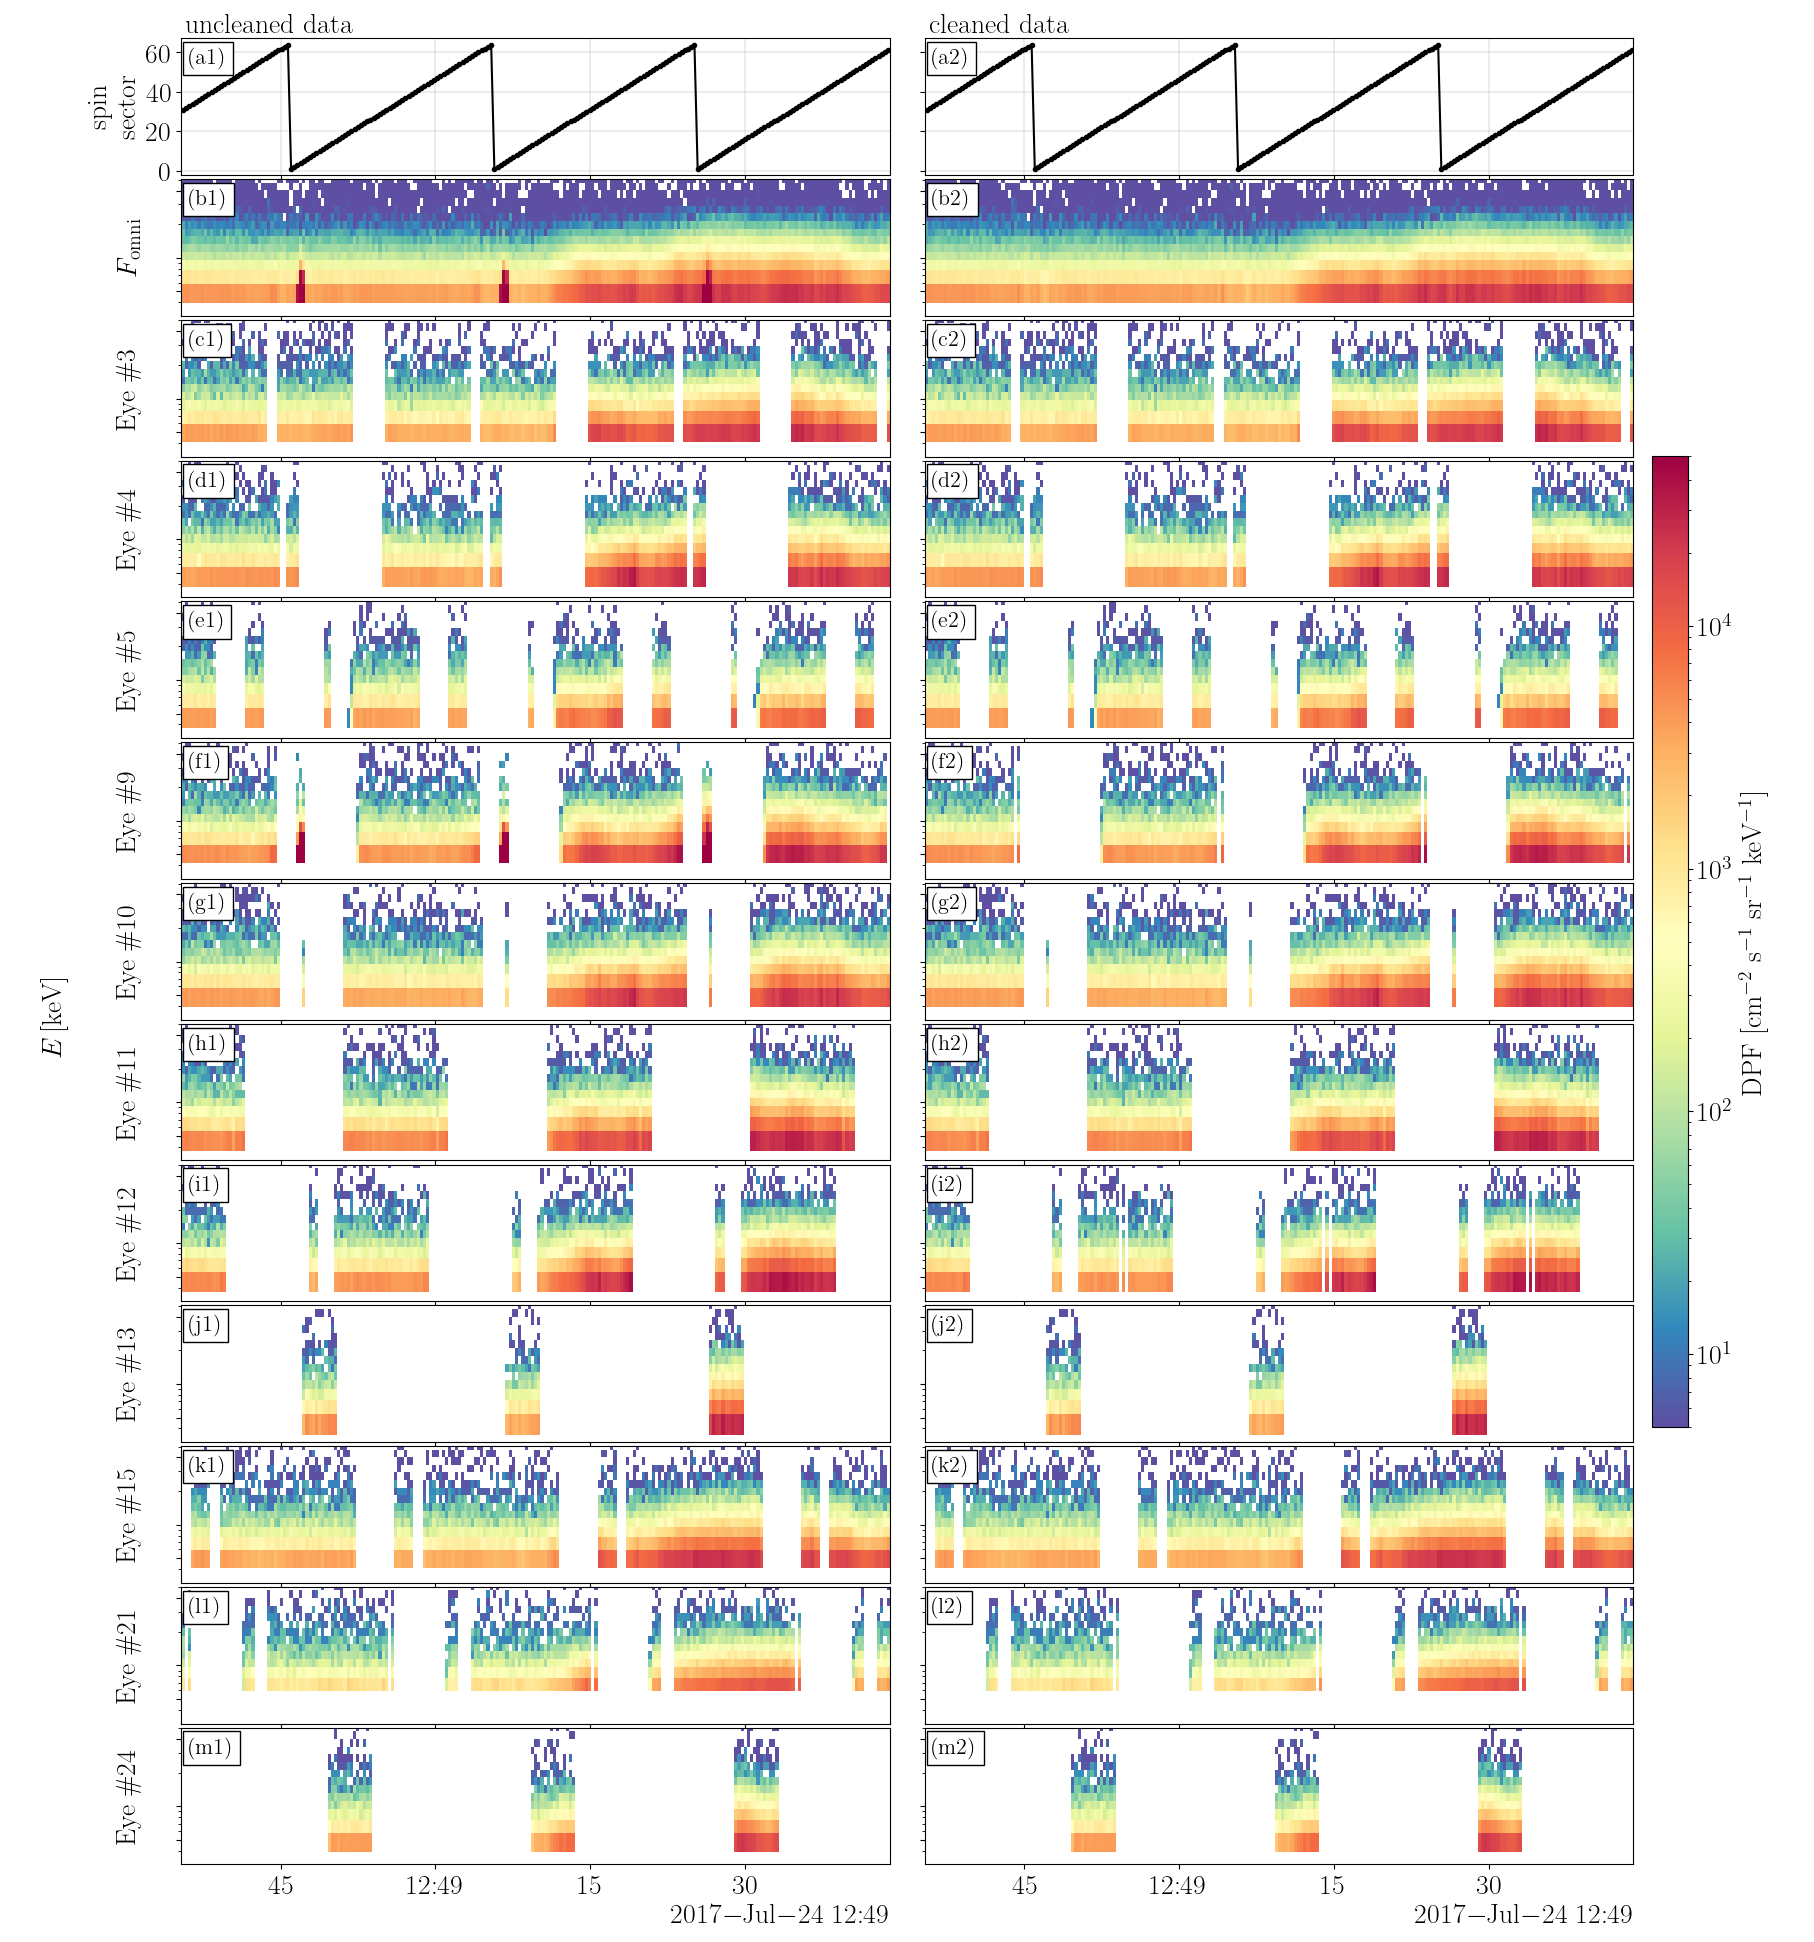

In [8]:

mms_id = 3

def get_eyes(dpf_feeps_e_corr, mms_id):
    """
    Get the eyes of the data
    """
    
    sensor_ids_data = []    
    for sensor_id in list(dpf_feeps_e_corr[mms_id].data_vars.keys()):

        if sensor_id[:3] in ["top", "bot"]:

            sensor_ids_data.append(dpf_feeps_e_corr[mms_id][sensor_id])

    new_sensor_ids_data = []
    for i, sensor_id_data in enumerate(sensor_ids_data):

        if np.isnan(sensor_id_data.data).all():
            continue
        new_sensor_ids_data.append(sensor_id_data)
    
    return new_sensor_ids_data

sensor_ids_data = get_eyes(dpf_feeps_e_corr, mms_id)
sensor_ids_data_new = get_eyes(dpf_feeps_e_corr_new, mms_id)

spinsect = dpf_feeps_e_corr[mms_id].spinsectnum

pt = 1./72.27
fig_width = 397.48499 * pt * 3.3 
fig_height = 668.4975 * pt * 2.1 
figsize=(fig_width, fig_height)
fig, axs = plt.subplots(len(sensor_ids_data) + 2, 2, figsize=figsize, sharex=True,)
fig.subplots_adjust(hspace=0.03, right=0.9, wspace = 0.05, left = 0.1, top = 0.98, bottom = 0.04)

plot_line(axs[0, 0], spinsect + 1, color="k", marker = '.')
plot_line(axs[0, 1], spinsect + 1, color="k", marker = '.')
axs[0, 0].set_ylabel("spin\n sector", )


axs[1, 0]= plot_spectr(axs[1, 0], dpf_feeps_omni_e[mms_id], yscale="log", cscale="log", cmap = "Spectral_r", clim = [5e0, 5e4], colorbar='none')
axs[1, 1], caxs = plot_spectr(axs[1, 1], dpf_feeps_omni_e_new[mms_id], yscale="log", cscale="log", cmap = "Spectral_r", clim = [5e0, 5e4],)
axs[1, 0].set_ylabel("$F_{\\rm omni}$", )

for i, sensor_id_data in enumerate(sensor_ids_data):
    axs[i+2, 0] = plot_spectr(axs[i+2, 0], sensor_id_data, yscale="log", cscale="log", cmap = "Spectral_r", clim = [5e0, 5e4], colorbar='none')
    num = int(sensor_id_data.name.split("-")[1])

    if sensor_id_data.name.split("-")[0] == "bottom":
        num = num + 12


    axs[i +2, 0].set_ylabel(ylabel = f'Eye \#{num}' ,  color = "black",)


    if i == len(sensor_ids_data)/2 - 0.5 or i == len(sensor_ids_data)/2:

        axs[i+2, 0].text(-0.18, 0.8, s = "$E\,[\mathrm{keV}]$", transform = axs[i+2, 0].transAxes, ha = "center", weight = "bold", rotation = 90, )
for i, sensor_id_data in enumerate(sensor_ids_data_new):
    axs[i+2, 1] = plot_spectr(axs[i+2, 1], sensor_id_data, yscale="log", cscale="log", cmap = "Spectral_r", clim = [5e0, 5e4], colorbar='none')
    num = int(sensor_id_data.name.split("-")[1])

    if sensor_id_data.name.split("-")[0] == "bottom":
        num = num + 12

caxs.set_position([0.91, 0.265, 0.02, 0.5])
caxs.set_ylabel("DPF [cm$^{-2}$ s$^{-1}$ sr$^{-1}$ keV$^{-1}$]",  y = 0.5, x = 2.5)

fig.align_ylabels(axs)
make_labels(axs[:, 0], pos = (0.01, 0.81), bbox=dict(facecolor='white', edgecolor='black',), num = "1", fontsize = 16)
make_labels(axs[:, 1], pos = (0.01, 0.81), bbox=dict(facecolor='white', edgecolor='black',), num = "2", fontsize = 16)

axs[0,0].text(0.005, 1.04, s = "uncleaned data", transform = axs[0,0].transAxes, ha = "left", weight = "bold",)
axs[0,1].text(0.005, 1.04, s = "cleaned data", transform = axs[0,1].transAxes, ha = "left", weight = "bold", )

[ax.set_yticks([5e1, 1e2, 4e2], labels = [r"$5 \times 10^1$", r"$10^2$", r"$4 \times 10^2$"], fontsize = 16) for ax in axs.flatten() if ax != axs[0,0] and ax != axs[0,1]]
[ax.sharey(axs[1,0]) for ax in axs.flatten() if ax != axs[0,0] and ax != axs[0,1]]
[ax.set_yticklabels([]) for ax in axs[:,1].flatten()]


In [9]:
ic = 3
feeps_data_vars = list(dpf_feeps_e_corr[ic].data_vars.keys())
spin_sect = dpf_feeps_e_corr[ic].spinsectnum
i_en = 3
top_eyes_keys = [data_var for data_var in feeps_data_vars if "top" in data_var]
bot_eyes_keys = [data_var for data_var in feeps_data_vars if "bot" in data_var]

table = np.empty(shape = (24, 64))*np.nan

for i, key in enumerate(top_eyes_keys):
    key_id = int(key.split("-")[1])
    
    for ss in np.arange(0, 64):
        
        times_in_ss = dpf_feeps_e_corr[ic].where(dpf_feeps_e_corr[ic].spinsectnum == ss, drop =True,).time
        data_in_ss = dpf_feeps_e_corr[ic][key].sel(time = times_in_ss).data[:,i_en]
        data_in_ss = np.nansum(data_in_ss, axis = 0)
        # data_in_ss = np.nansum(dpf_feeps_alle_e[0][key].sel(spinsectnum = ss).data, axis = 0)
        table[key_id-1, ss] = data_in_ss

for i, key in enumerate(bot_eyes_keys):
    key_id = int(key.split("-")[1])
    # i = i+12
    for ss in np.arange(0, 64):
        
        times_in_ss = dpf_feeps_e_corr[ic].where(dpf_feeps_e_corr[ic].spinsectnum == ss, drop =True,).time
        data_in_ss = dpf_feeps_e_corr[ic][key].sel(time = times_in_ss).data[:,i_en]
        data_in_ss = np.nansum(data_in_ss, axis = 0)
        # data_in_ss = np.nansum(dpf_feeps_alle_e[0][key].sel(spinsectnum = ss).data, axis = 0)
        table[key_id-1 + 12, ss] = data_in_ss

In [10]:

def reject_outliers(data):

    q95 = np.nanquantile(data, q = 0.995)
    data_clean = np.where(data<q95, data, np.nan)

    return data_clean

table_clean = np.empty(shape = (24, 64))*np.nan
table_clean = reject_outliers(table,)


In [11]:
table = np.where(table == 0, np.nan, table)
table_clean = np.where(table_clean == 0, np.nan, table_clean)

nans = np.isnan(table)
nans_clean = np.isnan(table_clean)

new_nans = nans_clean & ~nans

new_nans_indices = np.argwhere(new_nans)
new_nans_indices

sl_cont_table = np.zeros_like(table)
sl_cont_table[nans] = np.nan
sl_cont_table[new_nans] = 2

sl_cont_table = np.where(np.isnan(sl_cont_table) == True, 1, sl_cont_table)

sl_cont_table_old = np.where(np.isnan(table) == True, 1, 0)


In [12]:
import matplotlib
matplotlib.rcParams["text.usetex"] = True
matplotlib.rcParams["font.family"] = "serif"

matplotlib.rcParams["font.size"] = "24"

array([<Axes: ylabel='FEEPS Eye Number'>, <Axes: >], dtype=object)

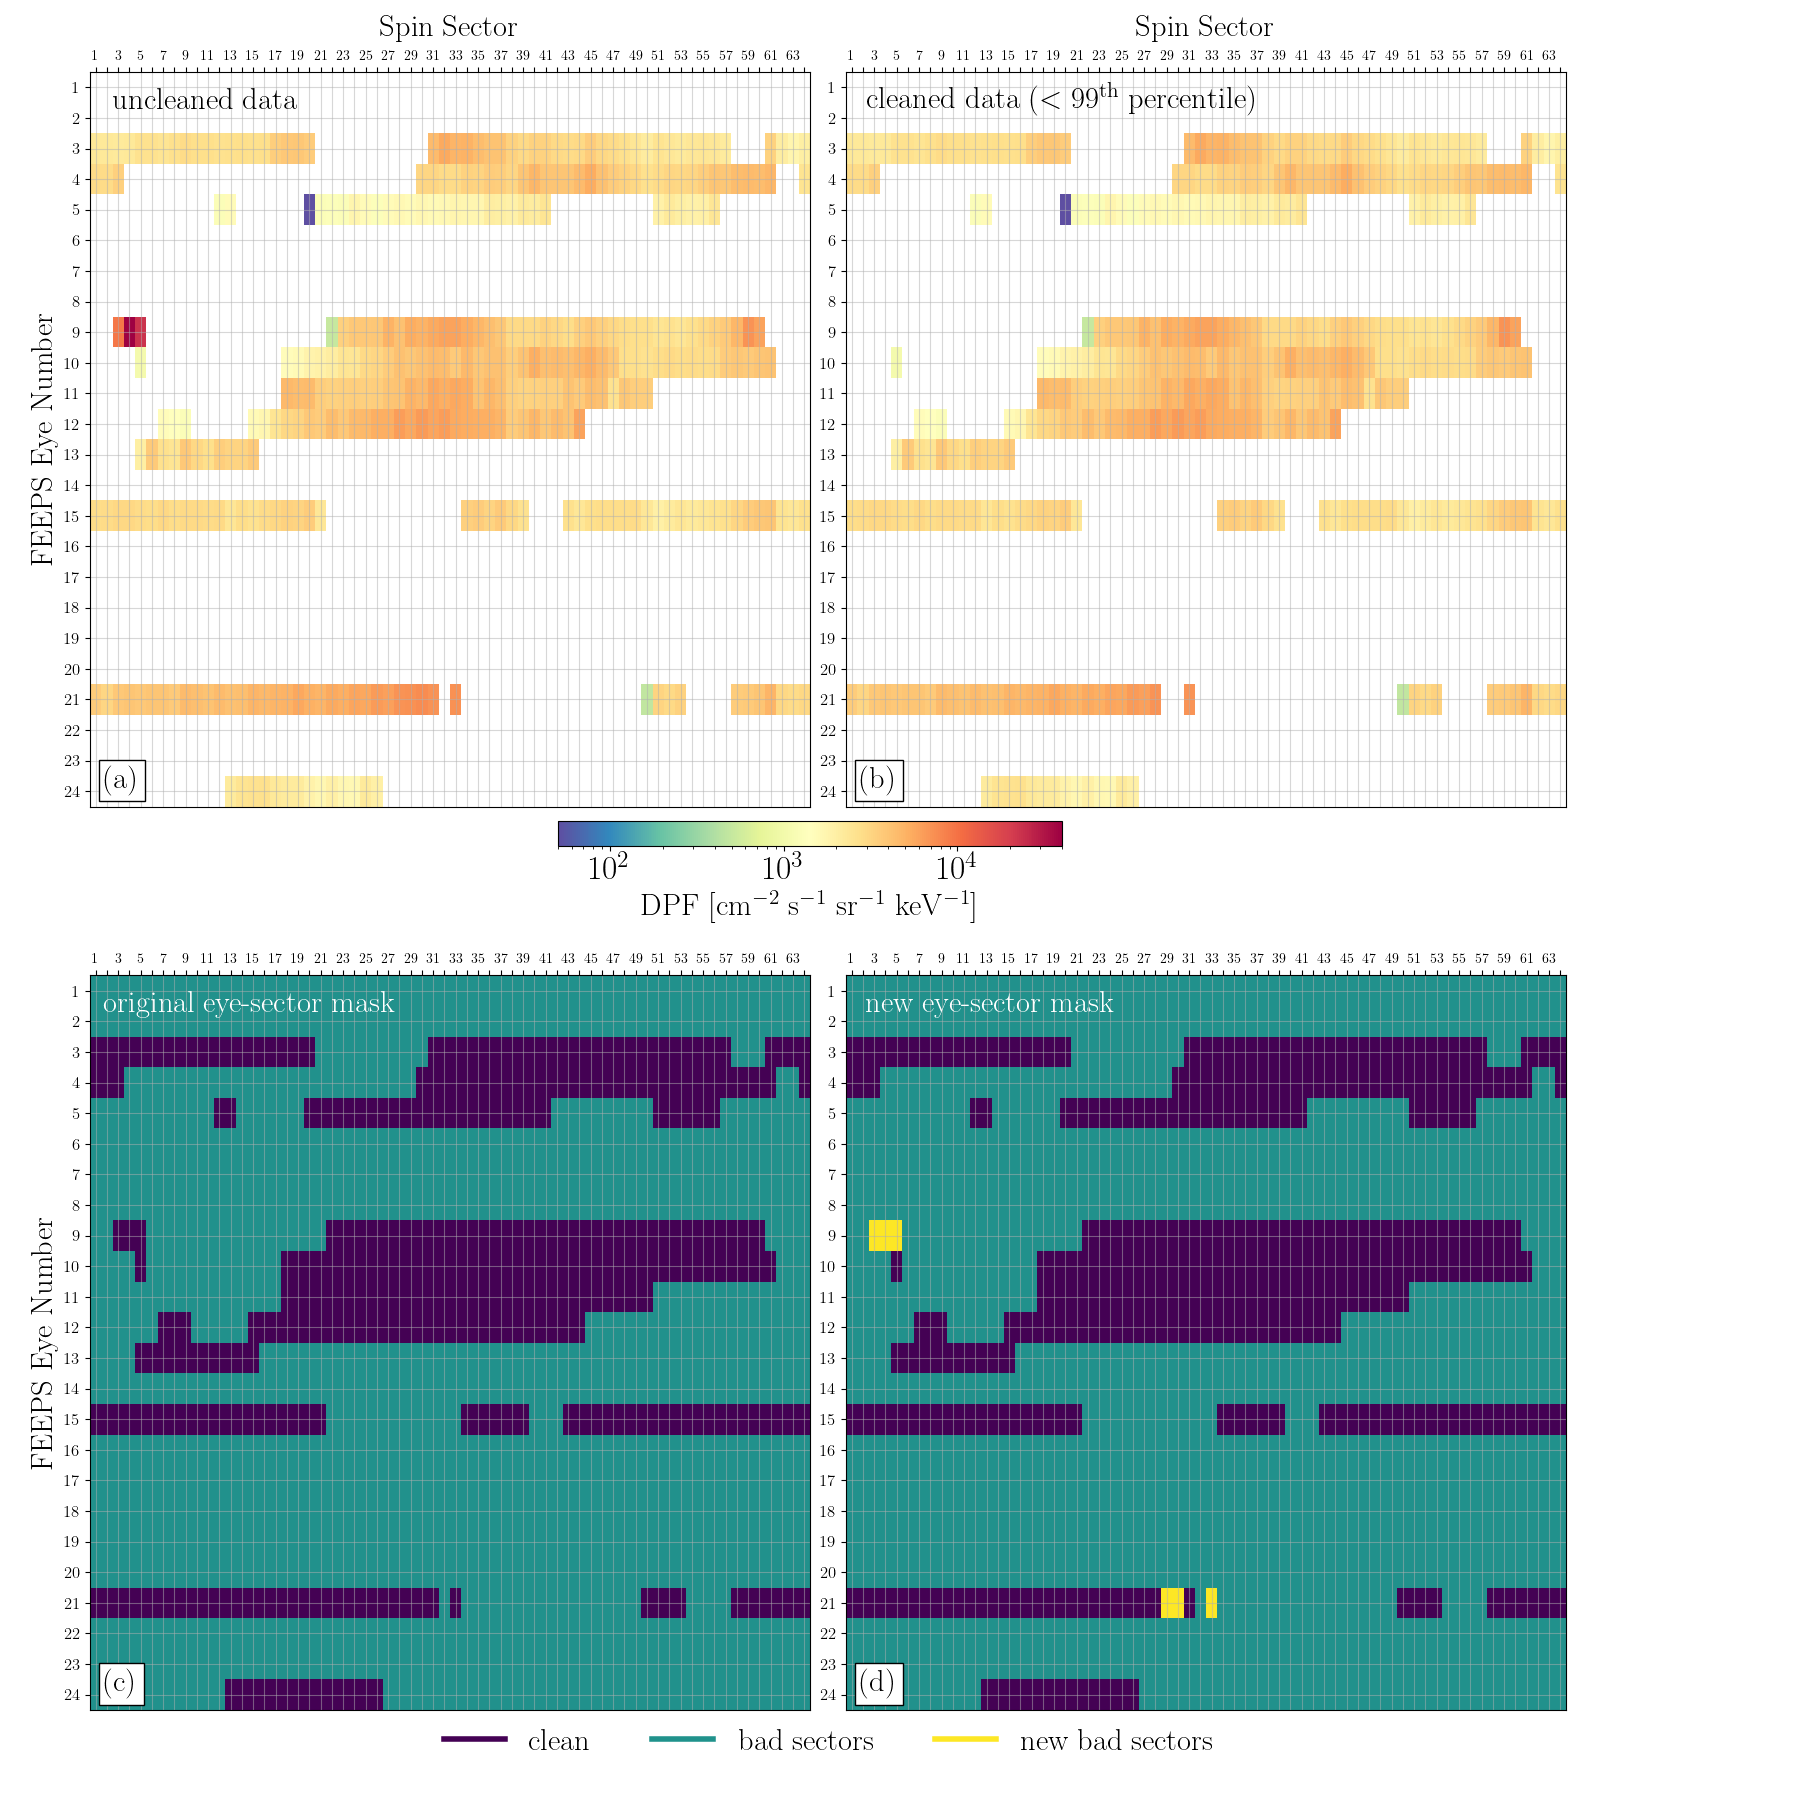

In [21]:
import matplotlib
import matplotlib.colors

text_fs = 22

fig, axs = plt.subplots(2,2, figsize=(18, 18))
fig.subplots_adjust(hspace=0.23, left = 0.05, right = 0.87, top = 0.96, bottom = 0.05, wspace=0.05, )

X = np.arange(0.5, 65, 1)
Y = np.arange(0.5, 25, 1)

plot_table = axs[0,0].pcolormesh(X, Y, table, cmap = "Spectral_r",norm=matplotlib.colors.LogNorm(), clim = [5e1, 4e4],)
axs[0,0].invert_yaxis()
axs[0,0].xaxis.tick_top()
cbar = fig.colorbar(plot_table, ax = axs[0,0], location = "bottom" ,  pad = 0-0.15,  orientation = "horizontal",)
cbar.ax.set_position([0.05, 0.53, 0.8, 0.014],)
# cbar.set_ylabel(ylabel = "$\langle DPF \\rangle $[cm$^{-2}$ s$^{-1}$ sr$^{-1}$ keV$^{-1}$]", fontsize = text_fs, labelpad = 15, rotation = 0, loc = "center")
cbar.set_label(label = "DPF [$\\rm {cm^{-2}}~s^{-1}~sr^{-1}~keV^{-1}$]", fontsize = text_fs)
# cbar.ax.set_ylabel(ylabel = "DPF [cm$^{-2}$ s$^{-1}$ sr$^{-1}$ keV$^{-1}$]", fontsize = 16, labelpad = 15, rotation = 0)

# cbar_lims = matplotlib.colors.LogNorm(vmin = cbar.vmin, vmax = cbar.vmax)
plot_table_clean = axs[0,1].pcolormesh(X, Y, table_clean, cmap = "Spectral_r", clim = [5e1, 4e4], norm =matplotlib.colors.LogNorm(),)
axs[0,1].invert_yaxis()
axs[0,1].xaxis.tick_top()
# axs[0].text(s = "Mean DPF per eye-sector pair", x = 1.05, y = 1.05, transform = axs[0].transAxes, ha = "center", fontsize = 18)
# fig.colorbar(plot_table_clean, ax = axs[1], label = "DPF [cm$^{-2}$ s$^{-1}$ sr$^{-1}$ keV$^{-1}$]", )
axs[0,0].text(s = "uncleaned data", x = 0.16, y = 0.95, transform = axs[0,0].transAxes, ha = "center", fontsize = text_fs, weight = "bold")
axs[0,1].text(s = "cleaned data ($<99^{\\rm th}$ percentile)", x = 0.3, y = 0.95, transform = axs[0,1].transAxes, ha = "center", fontsize = text_fs, weight = "bold")
[ax.set_xticks(np.arange(1, 65, 1)) for ax in axs[0,:].flatten()]

for ax in axs[0,:].flatten():
    for label in ax.xaxis.get_ticklabels()[1::2]:
        label.set_visible(False)

[ax.set_yticks(np.arange(1, 25, 1), ) for ax in axs[0,:].flatten()]
[ax.tick_params(axis = "x", labelsize = 10) for ax in axs[0,:].flatten()]
[ax.tick_params(axis = "y", labelsize = 12) for ax in axs[0,:].flatten()]
[ax.grid(which = "major", alpha= 0.5) for ax in axs[0,:].flatten()]

axs[0,0].set_ylabel("FEEPS Eye Number", fontsize = text_fs)
axs[0,0].set_xlabel("Spin Sector", fontsize = text_fs, labelpad = 10)
axs[0,1].set_xlabel("Spin Sector", fontsize = text_fs, labelpad = 10)

[axs[0,i].xaxis.set_label_position("top") for i in range(2)]

from matplotlib.lines import Line2D
cmap = matplotlib.colormaps["viridis"]
cmap_def = cmap(np.linspace(0, 1, 100))
color_masks = [cmap_def[0], cmap_def[int(len(cmap_def)/2)], cmap_def[-1]]
custom_handles = [Line2D([0], [0], color=color, lw=4) for color in color_masks]


plot_table = axs[1,0].pcolormesh(X, Y, sl_cont_table_old,  vmin = 0, vmax = 2, cmap = "viridis",)
axs[1,0].invert_yaxis()
axs[1,0].xaxis.tick_top()
# cbar = fig.colorbar(plot_table, ax = axs[0], location = "bottom" ,  pad = 0-0.15)
# cbar.ax.set_position([0.04, 0.1, 0.8, 0.02],)
# cbar.set_ticklabels([])
# cbar.set_ticks([])
plot_table_clean = axs[1,1].pcolormesh(X, Y, sl_cont_table, vmin = 0, vmax = 2, cmap = "viridis", )
axs[1,1].invert_yaxis()
axs[1,1].xaxis.tick_top()

axs[1,0].legend(custom_handles, ["clean", "bad sectors", "new bad sectors"], loc = "lower right", fontsize = text_fs, bbox_to_anchor=(1.6, -0.1), ncol = 3, frameon = False)
axs[1, 0].set_ylabel("FEEPS Eye Number", fontsize = text_fs)
axs[1,0].text(s = "original eye-sector mask", x = 0.22, y = 0.95, transform = axs[1,0].transAxes, ha = "center", fontsize = text_fs, weight = "bold", color = "white")
axs[1,1].text(s = "new eye-sector mask", x = 0.2, y = 0.95, transform = axs[1,1].transAxes, ha = "center", fontsize = text_fs, weight = "bold", color = "white")
[ax.set_xticks(np.arange(1, 65, 1)) for ax in axs[1,:].flatten()]

for ax in axs[1,:].flatten():
    for label in ax.xaxis.get_ticklabels()[1::2]:
        label.set_visible(False)
[ax.set_yticks(np.arange(1, 25, 1), ) for ax in axs[1,:].flatten()]
[ax.tick_params(axis = "x", labelsize = 10) for ax in axs[1,:].flatten()]
[ax.tick_params(axis = "y", labelsize = 12) for ax in axs[1,:].flatten()]
[ax.grid(which = "major", alpha= 0.5) for ax in axs[1,:].flatten()]
make_labels(axs[0,:], pos = (0.02, 0.025), bbox=dict(facecolor='white', edgecolor='black',), fontsize = text_fs, pad = 0)
make_labels(axs[1,:], pos = (0.02, 0.025), bbox=dict(facecolor='white', edgecolor='black',), fontsize = text_fs, pad = 2)
# fig.savefig(f"paper_figs/SI_figure_2.png", dpi = 500, bbox_inches = "tight")

In [14]:
new_cs = new_nans_indices + np.array([1,0])
dpf_feeps_e_corr_new = deepcopy(dpf_feeps_e_corr)

for cs in new_cs:

    eye_id = int(cs[0])
    ss = int(cs[1])
    if eye_id <= 12:

        dpf_feeps_e_corr_new[ic][f"top-{eye_id:d}"] = xr.where(dpf_feeps_e_corr_new[ic]["spinsectnum"] == ss, np.nan , dpf_feeps_e_corr_new[ic][f"top-{eye_id:d}"])
    else:
        dpf_feeps_e_corr_new[ic][f"bottom-{eye_id - 12:d}"] = xr.where(dpf_feeps_e_corr_new[ic]["spinsectnum"] == ss, np.nan , dpf_feeps_e_corr_new[ic][f"bottom-{eye_id - 12:d}"])



In [15]:
energy_channels_sc = [ [np.nan, 1, 1, 1], 
                [1, 2, 2, 2], 
                [2, 3, 3, 3], 
                [3, 4, 4, 4], 
                [4, 5, 5, 5], 
                [5, 6, 6, 6], 
                [6, 7, 7, 7], 
                [7, 8, 8, 8], 
                [np.nan, 9, 9, 9], 
                [10, 10, 10, 10], 
                [11, 11, 11, 11], 
                [12, 12, 12, 12], 
                [13, 13, 13, 13], 
                [14, 14, 14, 14], 
                [15, 15, 15, 15]]

In [16]:
feeps_mms_sc_energies = [dpf_feeps_omni_e_new[i].energy.values for i in range(4)]

In [18]:
matplotlib.rcParams["text.usetex"] = True
matplotlib.rcParams["font.family"] = "serif"

matplotlib.rcParams["font.size"] = "24"

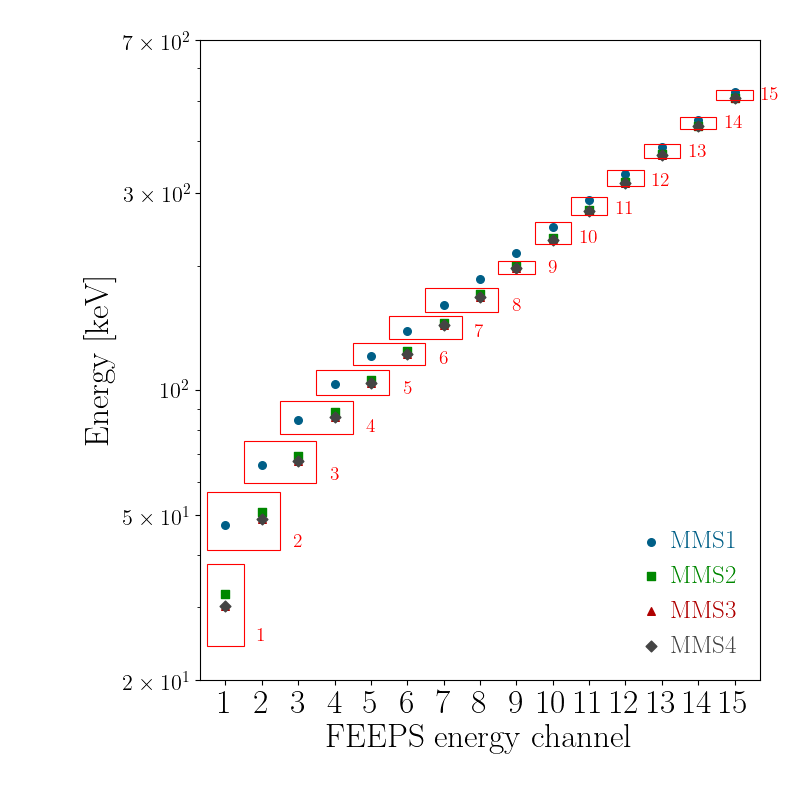

In [22]:
fig, axs = plt.subplots(figsize = (8,8))
fig.subplots_adjust(hspace=0.0, left = 0.25, right = 0.95, top = 0.95, bottom = 0.15, )
markers = ['o', 's', '^', 'D']
for i in range(4):

    axs.scatter([j for j in range(1, 16)], feeps_mms_sc_energies[i], marker = markers[i], label = f"MMS{i+1}", alpha = 1, s= 30)
axs.legend(fontsize = 18, loc = "lower right",  ncol=1,
               frameon = False, labelcolor = "linecolor",
               handlelength = 0,  )


axs.set_yscale("log")
axs.set_ylabel("Energy [keV]")
axs.set_xlabel("FEEPS energy channel")
axs.set_yticks(np.array([2e1, 5e1, 1e2, 3e2, 7e2]), labels= [r"$2 \times 10^1$", r"$5 \times 10^1$", r"$10^2$", r"$3 \times 10^2$", r"$7 \times 10^2$"], fontsize = 16, minor = False,)

axs.set_xticks(np.arange(1, 16, 1))


for i in range(len(energy_channels_sc)):

    rec_y_mean = np.nanmean([feeps_mms_sc_energies[j][energy_channels_sc[i][j] -1 ] for j in range(4) if not np.isnan(energy_channels_sc[i][j])])
    rec_y_min = np.nanmin([feeps_mms_sc_energies[j][energy_channels_sc[i][j] - 1] for j in range(4) if not np.isnan(energy_channels_sc[i][j])]) - 6
    rec_y_max = np.nanmax([feeps_mms_sc_energies[j][energy_channels_sc[i][j] - 1] for j in range(4) if not np.isnan(energy_channels_sc[i][j])]) +6
    # print(rec_y_min, rec_y_max)
    rec_height = rec_y_max - rec_y_min 

    rec_x_min = np.nanmin(np.array(energy_channels_sc[i])) - 0.5
    rec_x_max = np.nanmax(np.array(energy_channels_sc[i])) + 0.5
    rec_width = rec_x_max - rec_x_min
    rect = patches.Rectangle((rec_x_min, rec_y_min), rec_width, rec_height, linewidth=0.8, edgecolor='red', facecolor='none', alpha = 1)
    axs.text(i+1+1, rec_y_min + rec_height*0.05, s = f"{i+1}", ha = "center", color = "red", fontsize = 14, weight = "bold")
    
    axs.add_patch(rect)
# fig.savefig(f"paper_figs/SI_figure_3.png", dpi = 500, bbox_inches = "tight")